## Contexte
Dans le contexte du jeu de données sur le cancer du sein de l'Université de Californie à Irvine (UCI), la colonne "Classe" représente la variable cible que l'on cherche à prédire. Cette colonne contient des valeurs qui indiquent la nature de la tumeur, qui peut être bénigne (non cancéreuse) ou maligne (cancéreuse).

Voici les valeurs typiques que vous pourriez rencontrer dans la colonne "Classe" :

0 : Indique une tumeur bénigne. Cela signifie que la tumeur n'est pas cancéreuse. <br>
1 : Indique une tumeur maligne. Cela signifie que la tumeur est cancéreuse.

Ainsi, dans ce contexte, la "Classe" représente la catégorie ou le type de cancer du sein, où chaque ligne du jeu de données représente un échantillon de tissu de sein avec diverses caractéristiques mesurées et la classe correspondante, indiquant si la tumeur est bénigne ou maligne.

In [85]:
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report


## 1. Data et Préparation des données :

In [11]:
# URL du jeu de données
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/breast-cancer-wisconsin.data"

# Télécharger le contenu de l'URL
response = requests.get(url)

# Vérifier si la requête a réussi
if response.status_code == 200:
    # Lire les données CSV
    data = pd.read_csv(url, header=None)
    # Définir les noms de colonnes
    column_names = ['Numéro d\'échantillon', 'Épaisseur de la masse', 'Uniformité de la taille des cellules', 
                     'Uniformité de la forme des cellules', 'Adhérence marginale', 'Taille des cellules épithéliales uniques', 
                     'Noyaux nus', 'Chromatine non uniforme', 'Nucléoles normaux', 'Mitoses', 'Classe']
    data.columns = column_names
    
    # Sélectionner les colonnes requises à partir du deuxième index
    data = data.iloc[:, [1, 4, 5, 6, 8, 10]]
    
    # Remplacer les valeurs dans la colonne "Classe"
    data['Classe'] = data['Classe'].replace({2: 0, 4: 1})
    
    print("Les données ont été importées avec succès !")
else:
    print("Erreur lors de la récupération des données. Le code de statut HTTP est", response.status_code)


Les données ont été importées avec succès !


In [13]:
data.head()

,Épaisseur de la masse,Adhérence marginale,Taille des cellules épithéliales uniques,Noyaux nus,Nucléoles normaux,Classe
0,5,1,2,1,1,0
1,5,5,7,10,2,0
2,3,1,2,2,1,0
3,6,1,3,4,7,0
4,4,3,2,1,1,0


In [18]:
data.describe()

,Épaisseur de la masse,Adhérence marginale,Taille des cellules épithéliales uniques,Nucléoles normaux,Classe
count,699.000000,699.000000,699.000000,699.000000,699.000000
mean,4.417740,2.806867,3.216023,2.866953,0.344778
std,2.815741,2.855379,2.214300,3.053634,0.475636
min,1.000000,1.000000,1.000000,1.000000,0.000000
25%,2.000000,1.000000,2.000000,1.000000,0.000000
50%,4.000000,1.000000,2.000000,1.000000,0.000000
75%,6.000000,4.000000,4.000000,4.000000,1.000000
max,10.000000,10.000000,10.000000,10.000000,1.000000


In [67]:
# Remplacer les valeurs manquantes par la moyenne des colonnes
data_brut = data.replace('?', np.nan)
data_brut = data_brut.fillna(data.mean())

# Normalisation Min-Max
scaler = MinMaxScaler()
data_set = scaler.fit_transform(data_brut)

missing_values = np.isnan(data_set).sum()
missing_values

0

In [68]:
data_set = pd.DataFrame(data_set)
# Définir les noms de colonnes en français
data_set.columns = ['Épaisseur de la masse', 'Adhérence marginale', 
                    'Taille des cellules épithéliales uniques', 
                    'Noyaux nus', 'Nucléoles normaux', 'Classe']
    
data_set.head()

,Épaisseur de la masse,Adhérence marginale,Taille des cellules épithéliales uniques,Noyaux nus,Nucléoles normaux,Classe
0,0.444444,0.000000,0.111111,0.000000,0.000000,0.0
1,0.444444,0.444444,0.666667,1.000000,0.111111,0.0
2,0.222222,0.000000,0.111111,0.111111,0.000000,0.0
3,0.555556,0.000000,0.222222,0.333333,0.666667,0.0
4,0.333333,0.222222,0.111111,0.000000,0.000000,0.0


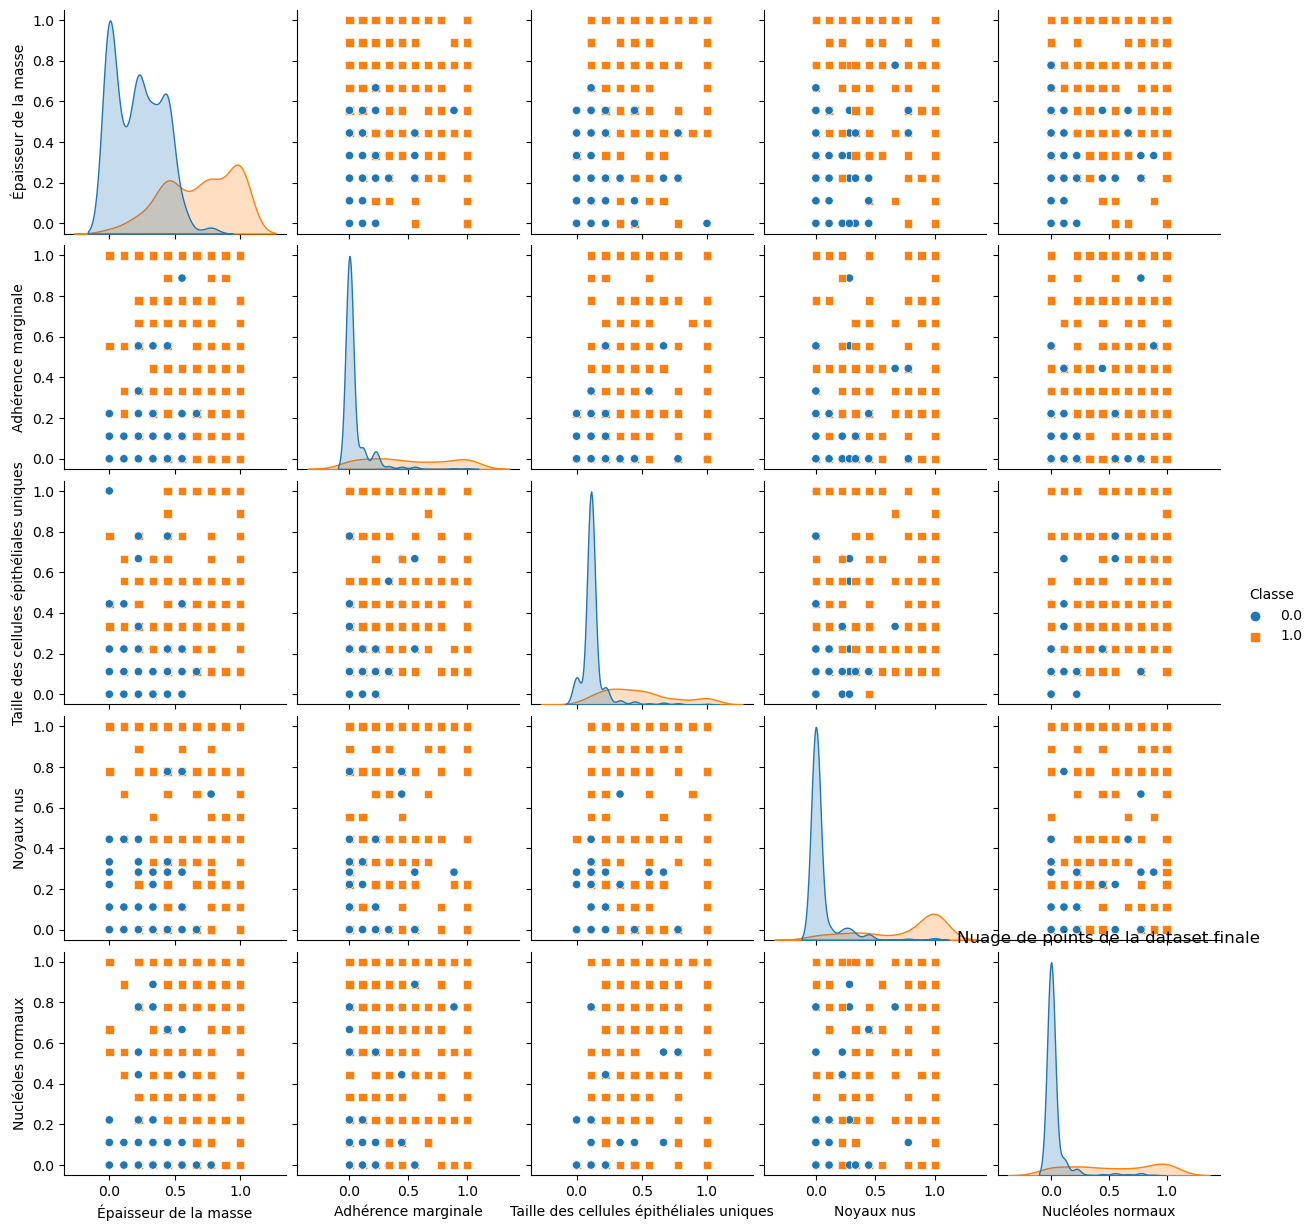

In [69]:
# Nuage de points avec seaborn
sns.pairplot(data_set, hue='Classe', markers=["o", "s"])
plt.title("Nuage de points de la dataset finale")
plt.show()

In [70]:
# Matrice de corrélation
corr_matrix = data_set.corr()
corr_matrix

,Épaisseur de la masse,Adhérence marginale,Taille des cellules épithéliales uniques,Noyaux nus,Nucléoles normaux,Classe
Épaisseur de la masse,1.000000,0.486356,0.521816,0.587300,0.535835,0.716001
Adhérence marginale,0.486356,1.000000,0.599599,0.665049,0.603352,0.696800
Taille des cellules épithéliales uniques,0.521816,0.599599,1.000000,0.581261,0.628881,0.682785
Noyaux nus,0.587300,0.665049,0.581261,1.000000,0.577362,0.816050
Nucléoles normaux,0.535835,0.603352,0.628881,0.577362,1.000000,0.712244
Classe,0.716001,0.696800,0.682785,0.816050,0.712244,1.000000


In [73]:
# Diviser la data set en training set et test set (80% training, 20% test)

X = data_set.drop('Classe', axis=1)
y = data_set['Classe']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


## 2. Entraînement des modèles de base :

In [74]:
# Entraîner le modèle KNN
knn_model = KNeighborsClassifier(n_neighbors=5) 
knn_model.fit(X_train, y_train)
    
# Prédire sur l'ensemble de test
y_pred_knn = knn_model.predict(X_test)

In [79]:
# Entraîner le modèle ANN
model_ann = Sequential([
    Dense(32, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

model_ann.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_ann.fit(X_train, y_train, epochs=50, batch_size=32, validation_split=0.2)

# Prédire sur l'ensemble de test avec le modèle ANN
y_pred_ann_intermediaire = model_ann.predict(X_test)
y_pred_ann = np.where(y_pred_ann_intermediaire >= 0.5, 1, 0)


Epoch 1/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.7119 - loss: 0.6608 - val_accuracy: 0.9107 - val_loss: 0.6239
Epoch 2/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8997 - loss: 0.6046 - val_accuracy: 0.9286 - val_loss: 0.5726
Epoch 3/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9202 - loss: 0.5494 - val_accuracy: 0.9375 - val_loss: 0.5265
Epoch 4/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9345 - loss: 0.5118 - val_accuracy: 0.9375 - val_loss: 0.4850
Epoch 5/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9314 - loss: 0.4669 - val_accuracy: 0.9375 - val_loss: 0.4471
Epoch 6/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9425 - loss: 0.4236 - val_accuracy: 0.9286 - val_loss: 0.4101
Epoch 7/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9458 - loss: 0.3797 - val_accuracy: 0.9286 - val_loss: 0.3745
Epoch 8/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9691 - loss: 0.3230 - val_accuracy: 0.9464 - val_loss

In [81]:
# Entraîner le modèle Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
    
# Prédire sur l'ensemble de test
y_pred_dt = dt_model.predict(X_test)

### Méta-modèle :

In [83]:
# Nouveau DataFrame avec les prédictions des modèles de base
meta_data = pd.DataFrame({
    'KNN': y_pred_knn,
    'ANN': y_pred_ann.flatten(),
    'DecisionTree': y_pred_dt
})

X_meta_train, X_meta_test, y_meta_train, y_meta_test = train_test_split(meta_data, y_test, test_size=0.2, random_state=42)

# Entraînement du modèle Naive Bayes Classifier
nb_model = GaussianNB()
nb_model.fit(X_meta_train, y_meta_train)

# Prédiction sur l'ensemble de test
y_pred_meta = nb_model.predict(X_meta_test)


La précision du modèle Naive Bayes Classifier sur l'ensemble de test est de : 0.9642857142857143


In [84]:
# Rapport de classification
report = classification_report(y_meta_test, y_pred_meta)

print("Rapport de classification pour le modèle Naive Bayes Classifier :")
print(report)


Rapport de classification pour le modèle Naive Bayes Classifier :
              precision    recall  f1-score   support

         0.0       1.00      0.94      0.97        18
         1.0       0.91      1.00      0.95        10

    accuracy                           0.96        28
   macro avg       0.95      0.97      0.96        28
weighted avg       0.97      0.96      0.96        28



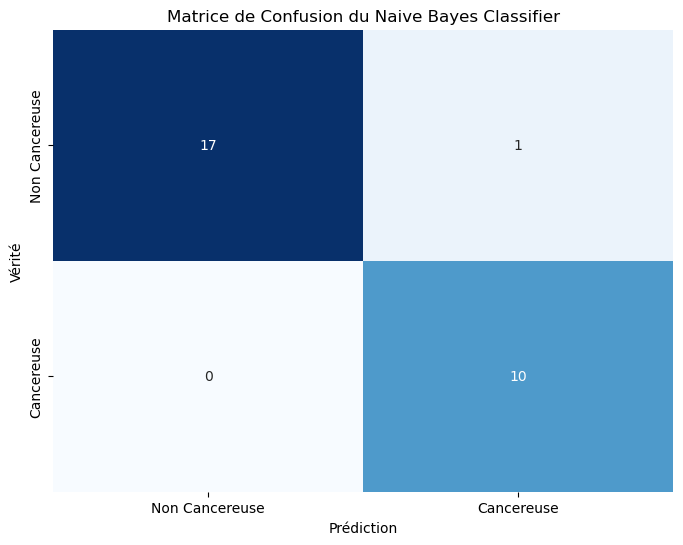

In [87]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Calculer la matrice de confusion
conf_matrix = confusion_matrix(y_meta_test, y_pred_meta)

# Tracer la matrice de confusion sous forme de heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, cmap="Blues", fmt="d", cbar=False, 
            xticklabels=['Non Cancereuse', 'Cancereuse'], yticklabels=['Non Cancereuse', 'Cancereuse'])
plt.xlabel('Prédiction')
plt.ylabel('Vérité')
plt.title('Matrice de Confusion du Naive Bayes Classifier')
plt.show()
